In [15]:
from ultralytics import YOLO

# Load baseline pre-trained model on COCO dataset for comparison
# model = YOLO('yolov8n.pt')

# Load our custom fine-tuned weights (Trained on Kaggle, best mAP50)
model = YOLO('../models/best.pt')

In [16]:
import os

txt_path = "../data/train/labels"
images_path = "../data/train/images"

# Fetch a label file to find a corresponding test image
txt_files = os.listdir(txt_path)
filename = txt_files[-1]

# Dynamically construct the image path from the label name to avoid hardcoding
image_name = os.path.splitext(filename)[0] + '.jpg'
image_file = os.path.join(images_path, image_name)

# Run inference (predict) on the selected image
results = model(image_file)


image 1/1 d:\PYTHON\ML_AI_PROJECTS\Traffic_Vision\notebooks\..\data\train\images\synthetic_0040.jpg: 448x640 1 Motorcycle, 90.3ms
Speed: 6.0ms preprocess, 90.3ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)


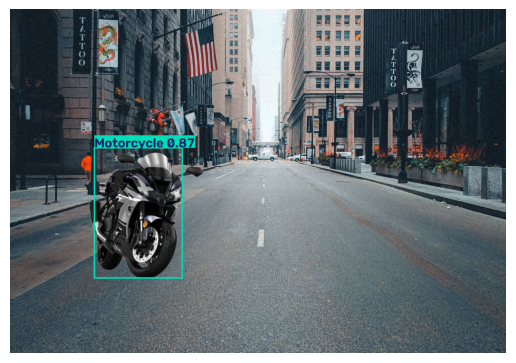

In [17]:
import cv2
import matplotlib.pyplot as plt

# Extract the image array with drawn bounding boxes, labels, and confidences from YOLO results
annotated_img = results[0].plot()

# Convert BGR (OpenCV default format) to RGB (Matplotlib default) for correct color rendering
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))

# Hide coordinate axes for a cleaner presentation of the detected objects
plt.axis('off')
plt.show()